# 08 - Dose plane × resistant-strain traits

Notebook 02 varied α, β_min and c at **one dose** (a0 = 2.15, i = 10); notebooks 03 and 04 varied one
dose each with the traits at base. At the base dose the
goal "remove R, keep S" is never met by changing α, β_min or c, because the dose is too low to push
either strain below one cell. This notebook asks the joint question:

**For which resistant strains is there any dose that removes R and keeps S, and how wide is that dose window?**

Two designs, both on the standard dose plane (a0: 22 values from 1 to 100; i: 21 values from 0.1 to 10; 462 doses):

| Table | Strains | Runs |
|---|---|---|
| `grid_dose_by_trait_single.csv.gz` | each of α, β_min, c varied alone on its standard 21-value axis | 3 × 21 × 462 = 29,106 |
| `grid_dose_by_trait_joint.csv.gz` | α, β_min, c varied together on a coarse grid (every fourth standard value plus base: 6 × 7 × 7 = 294 strains) | 294 × 462 = 135,828 |

Engine, endpoints and the extinction floor are the same as in every other notebook. If the tables
are missing they are recomputed here (about 4 minutes and 20 minutes on two cores).

**Two measures of success**

- **Goal doses:** number of the 462 grid doses with outcome "R eradicated, S survives" (extinction-floor runs).
- **Window ratio:** (lowest antibiotic dose that eradicates S) / (lowest antibiotic dose that eradicates R),
  at one inhibitor dose. Above 1 = a selective window exists; 1.2 = the dose may be up to 20% above the
  R-eradicating dose before S is lost too. If S survives every dose up to a0 = 100 the window is
  open-ended and the ratio is a lower bound. See `src/analysis/dose_window.py`.

In [1]:
from pathlib import Path
import sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(PROJECT_ROOT))
TABLES = PROJECT_ROOT / "results" / "tables"
TABLES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", None); pd.set_option("display.width", 160)

from src.analysis import sweep_engine as engine
from src.analysis.grid_runner import run_dose_by_trait, axis, coarse_axis, BASE_VALUES, TRAITS
from src.analysis.dose_window import windows, strain_summary
from src.analysis.plotting import OKABE_ITO, OUTCOME_COLORS, SHORT, label, outcome_map, outcome_counts, select

FORCE_RERUN = False
def run_or_load(design):
    path = TABLES / f"grid_dose_by_trait_{design}.csv.gz"
    if path.exists() and not FORCE_RERUN:
        return pd.read_csv(path)
    t0 = time.time()
    df = run_dose_by_trait(design)
    df.to_csv(path, index=False, float_format="%.8g")
    print(f"{design}: {len(df):,} runs in {time.time() - t0:.0f} s")
    return df

single = run_or_load("single")
joint = run_or_load("joint")
print(f"single-trait design: {len(single):,} runs | joint design: {len(joint):,} runs")
print("joint trait values:", {k: list(map(float, coarse_axis(k))) for k in TRAITS})

single-trait design: 29,106 runs | joint design: 135,828 runs
joint trait values: {'alpha': [0.75, 0.8, 0.85, 0.9, 0.95, 1.0], 'beta_min': [0.0, 0.2, 0.4, 0.6, 0.8, 0.9, 1.0], 'c': [0.0, 0.2, 0.4, 0.6, 0.7, 0.8, 1.0]}


## Outcomes over all doses and strains

In [2]:
pd.concat({"single-trait design": outcome_counts(single), "joint design": outcome_counts(joint)}, axis=1)

single-trait design           joint design          
                                        runs % of grid         runs % of grid
outcome_floor                                                                
R eradicated, S survives                 364      1.25         2302      1.69
community eradicated                    5824     20.01        19551     14.39
S eradicated, R survives                 761      2.61         3101      2.28
R suppressed                               6      0.02          105      0.08
S viable, R persists                   15215     52.27        54935     40.44
S not viable, R persists                6936     23.83        55834     41.11

## One trait at a time

Top row: number of grid doses that meet the goal. Bottom row: the best window ratio over all
inhibitor doses. The dashed line marks ratio = 1 (no window below it); the dotted line marks the base strain.

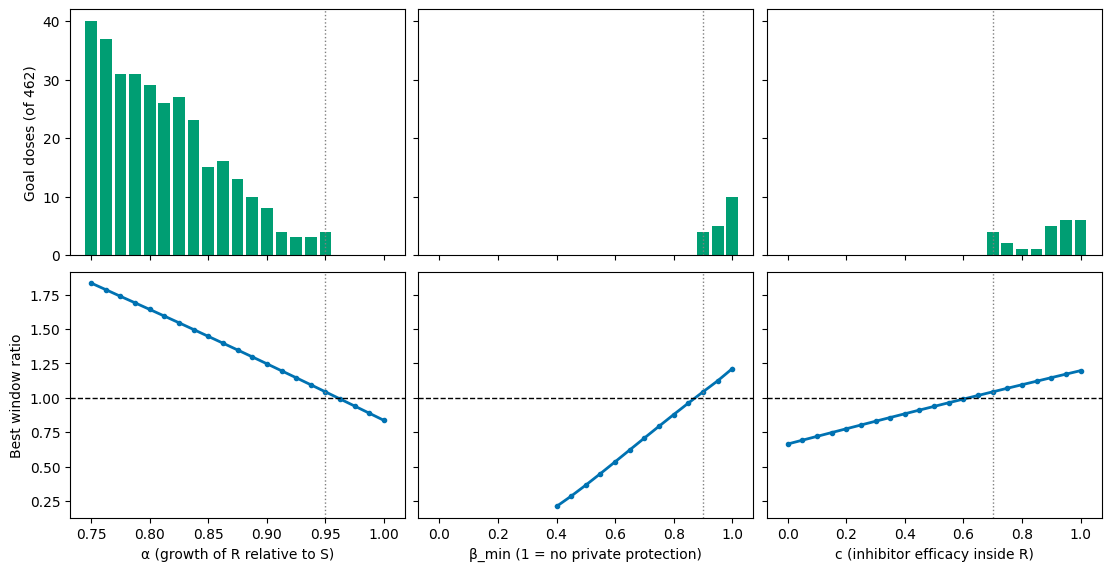

α: window exists for α from 0.75 to 0.95 | best ratio 1.83 at α = 0.75 | most goal doses 40 | open-ended windows: 0
β_min: window exists for β_min from 0.9 to 1 | best ratio 1.21 at β_min = 1 | most goal doses 10 | open-ended windows: 0
c: window exists for c from 0.65 to 1 | best ratio 1.20 at c = 1 | most goal doses 6 | open-ended windows: 0


In [3]:
summ = {t: strain_summary(single[single.varied == t]) for t in TRAITS}
fig, axes = plt.subplots(2, 3, figsize=(11, 5.6), constrained_layout=True, sharex="col", sharey="row")
for j, t in enumerate(TRAITS):
    s = summ[t]
    axes[0, j].bar(s[t], s.goal_doses, width=(s[t].iloc[1] - s[t].iloc[0]) * 0.8, color=OKABE_ITO["green"])
    axes[1, j].plot(s[t], s.best_window_ratio, color=OKABE_ITO["blue"], lw=2, marker="o", ms=3)
    axes[1, j].axhline(1, color="black", ls="--", lw=1)
    for ax in axes[:, j]:
        ax.axvline(BASE_VALUES[t], color="grey", ls=":", lw=1)
    axes[1, j].set_xlabel(label(t))
axes[0, 0].set_ylabel("Goal doses (of 462)")
axes[1, 0].set_ylabel("Best window ratio")
plt.show()
for t in TRAITS:
    s = summ[t]
    ok = s[s.best_window_ratio > 1]
    if len(ok) == 0:
        print(f"{SHORT[t]}: no window"); continue
    print(f"{SHORT[t]}: window exists for {SHORT[t]} from {ok[t].min():g} to {ok[t].max():g}",
          f"| best ratio {s.best_window_ratio.max():.2f} at {SHORT[t]} = {s.loc[s.best_window_ratio.idxmax(), t]:g}",
          f"| most goal doses {s.goal_doses.max()} | open-ended windows: {int(s.best_is_lower_bound.sum())}")

### Check: the window ratio agrees with the explicit extinction-floor runs

In [4]:
w_all = pd.concat([windows(single[single.varied == t]) for t in TRAITS], ignore_index=True)
bins = pd.cut(w_all.window_ratio, [0, 1, 1.1, 1.26, 1.6, 3])
check = w_all.groupby(bins, observed=True).goal_doses.agg(["count", "mean", "max"])
check.columns = ["strain × inhibitor-dose cases", "mean goal doses", "max goal doses"]
print("Neighbouring a0 grid doses differ by a factor of", round(float(axis("a0", include_base=False)[1] / axis("a0", include_base=False)[0]), 3))
assert w_all[~(w_all.window_ratio > 1)].goal_doses.sum() == 0, "goal met without a window"
print("Goal doses in cases with no window (ratio ≤ 1 or R never eradicated): 0")
check

Neighbouring a0 grid doses differ by a factor of 1.259
Goal doses in cases with no window (ratio ≤ 1 or R never eradicated): 0


,strain × inhibitor-dose cases,mean goal doses,max goal doses
window_ratio,,,
"(0.0, 1.0]",406,0.000000,0
"(1.0, 1.1]",81,0.320988,1
"(1.1, 1.26]",91,0.670330,1
"(1.26, 1.6]",107,1.504673,2
"(1.6, 3.0]",51,2.274510,3


### Dose maps as R becomes more costly

Outcome with the extinction floor on the dose plane, for four values of α (β_min and c at base).

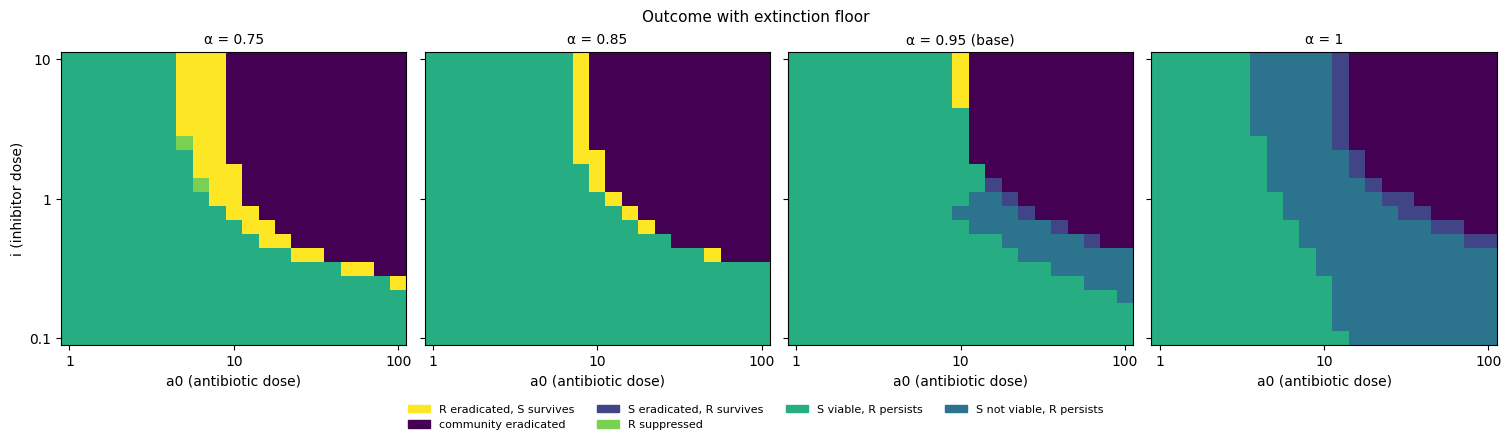

In [5]:
fig = outcome_map(single[single.varied == "alpha"], "a0", "i", "alpha", slice_values=[0.75, 0.85, 0.95, 1.0])
plt.show()

### Does more inhibitor widen the window?

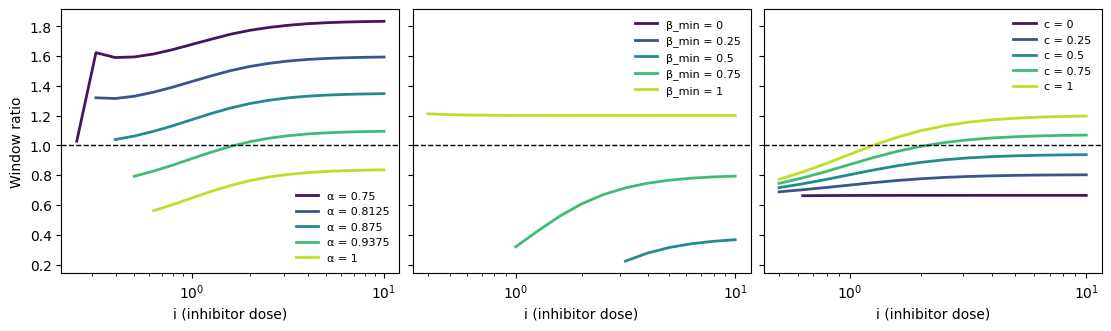

Distinct strains with a window: 26; widest window is at the highest inhibitor dose (i = 10) in 25 of them
Exception: [{'alpha': 0.95, 'beta_min': 1.0, 'c': 0.7, 'i_at_best_window': 0.398, 'best_window_ratio': 1.213}]


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), constrained_layout=True, sharey=True)
shades = plt.cm.viridis(np.linspace(0.05, 0.9, 5))
for ax, t in zip(axes, TRAITS):
    w = windows(single[single.varied == t])
    values = np.sort(w[t].unique())[::5]
    for v, col in zip(values, shades):
        s = w[np.isclose(w[t], v)].sort_values("i")
        ax.plot(s.i, s.window_ratio, color=col, lw=2, label=f"{SHORT[t]} = {v:g}")
    ax.axhline(1, color="black", ls="--", lw=1)
    ax.set_xscale("log"); ax.set_xlabel(label("i")); ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("Window ratio")
plt.show()
best_i = pd.concat(summ.values()).drop_duplicates(list(TRAITS))     # the base strain appears once per trait block
best_i = best_i[best_i.best_window_ratio > 1]
print(f"Distinct strains with a window: {len(best_i)}; widest window is at the highest inhibitor dose (i = 10) in "
      f"{np.isclose(best_i.i_at_best_window, 10).sum()} of them")
other = best_i[~np.isclose(best_i.i_at_best_window, 10)]
print("Exception:", other[list(TRAITS) + ["i_at_best_window", "best_window_ratio"]].round(3).to_dict("records"))

## All three traits together

Each panel is one value of β_min; each cell is one strain (α, c). Top: goal doses. Bottom: best window ratio
(white line = ratio 1; blank = R is never eradicated in the dose range).

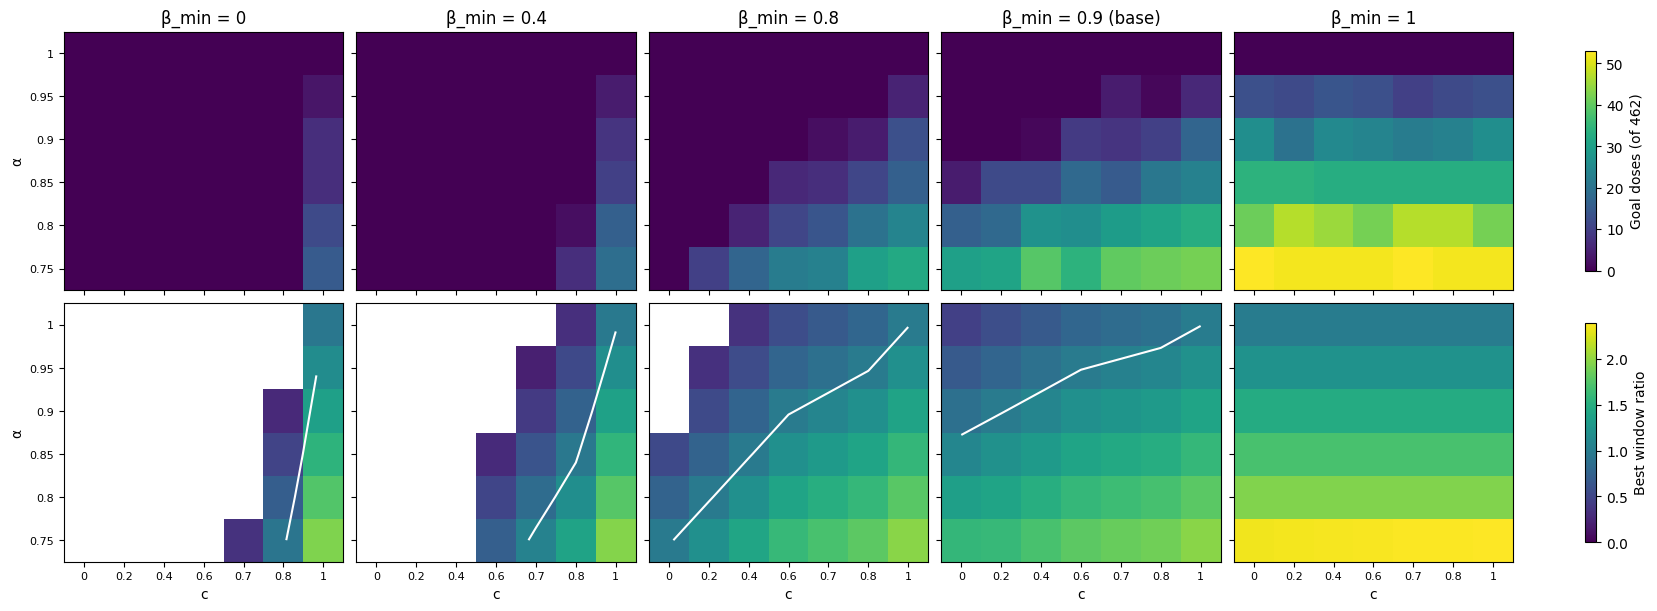

113 of 294 strains have a selective window; 112 have at least one goal dose on the grid


Widest fully measured window: 2.18 (α = 0.75, β_min = 1, c = 0, i = 0.32)
Widest with some private protection left (β_min ≤ 0.9): 1.97 (α = 0.75, β_min = 0.9, c = 1, i = 10)
Open-ended windows (S survives every dose up to a0 = 100): 7 strains, all with β_min = [1.0] and α = [0.75]; ratio at least 2.39


In [7]:
js = strain_summary(joint)
b_values = [0.0, 0.4, 0.8, 0.9, 1.0]
fig, axes = plt.subplots(2, len(b_values), figsize=(3.1 * len(b_values) + 1, 6), constrained_layout=True,
                         sharex=True, sharey=True)
for j, b in enumerate(b_values):
    s = js[np.isclose(js.beta_min, b)]
    for r, (col, cmap, vmax) in enumerate([("goal_doses", "viridis", js.goal_doses.max()),
                                           ("best_window_ratio", "viridis", np.nanmax(js.best_window_ratio))]):
        piv = s.pivot(index="alpha", columns="c", values=col)
        x = np.arange(len(piv.columns)); y = np.arange(len(piv.index))
        im = axes[r, j].pcolormesh(x, y, piv.values, cmap=cmap, vmin=0, vmax=vmax, shading="nearest")
        if r == 1 and np.nanmin(piv.values) < 1 < np.nanmax(piv.values):
            axes[r, j].contour(x, y, piv.values, levels=[1], colors="white", linewidths=1.5)
        axes[r, j].set_xticks(x); axes[r, j].set_xticklabels([f"{v:g}" for v in piv.columns], fontsize=8)
        axes[r, j].set_yticks(y); axes[r, j].set_yticklabels([f"{v:g}" for v in piv.index], fontsize=8)
        if j == len(b_values) - 1:
            fig.colorbar(im, ax=axes[r, :], shrink=0.85, label="Goal doses (of 462)" if r == 0 else "Best window ratio")
    axes[0, j].set_title(f"β_min = {b:g}" + (" (base)" if np.isclose(b, BASE_VALUES["beta_min"]) else ""))
    axes[1, j].set_xlabel("c")
axes[0, 0].set_ylabel("α"); axes[1, 0].set_ylabel("α")
plt.show()
has = js.best_window_ratio > 1
print(f"{has.sum()} of {len(js)} strains have a selective window; {(js.goal_doses > 0).sum()} have at least one goal dose on the grid")
w_joint = windows(joint)
top = w_joint[~w_joint.censored].sort_values("window_ratio", ascending=False).iloc[0]
print(f"Widest fully measured window: {top.window_ratio:.2f} (α = {top.alpha:g}, β_min = {top.beta_min:g}, c = {top.c:g}, i = {top.i:.2f})")
partial = w_joint[~w_joint.censored & (w_joint.beta_min <= 0.9)].sort_values("window_ratio", ascending=False).iloc[0]
print(f"Widest with some private protection left (β_min ≤ 0.9): {partial.window_ratio:.2f} (α = {partial.alpha:g}, β_min = {partial.beta_min:g}, c = {partial.c:g}, i = {partial.i:g})")
print(f"Open-ended windows (S survives every dose up to a0 = 100): {int(js.best_is_lower_bound.sum())} strains, "
      f"all with β_min = {sorted(map(float, js[js.best_is_lower_bound].beta_min.unique()))} and α = {sorted(map(float, js[js.best_is_lower_bound].alpha.unique()))}; ratio at least {js[js.best_is_lower_bound].best_window_ratio.max():.2f}")

In [8]:
top = js.sort_values("best_window_ratio", ascending=False).head(10).round(3)
print("Ten strains with the widest window (best_is_lower_bound = True: open-ended, the ratio is a lower bound):")
display(top)
by_b = js.groupby("beta_min").agg(strains=("alpha", "size"), with_window=("best_window_ratio", lambda s: (s > 1).sum()),
                                  widest_ratio=("best_window_ratio", "max"), most_goal_doses=("goal_doses", "max")).round(2)
by_b

Ten strains with the widest window (best_is_lower_bound = True: open-ended, the ratio is a lower bound):


,alpha,beta_min,c,goal_doses,inhibitor_doses_with_window,widest_measured_ratio,best_window_ratio,best_is_lower_bound,i_at_best_window,a0_R_at_best_window
48,0.75,1.0,1.0,52,18,2.181,2.395,True,0.251,41.755
47,0.75,1.0,0.8,52,18,2.181,2.384,True,0.251,41.943
46,0.75,1.0,0.7,53,18,2.182,2.379,True,0.251,42.037
45,0.75,1.0,0.6,52,18,2.182,2.373,True,0.251,42.132
44,0.75,1.0,0.4,52,18,2.182,2.363,True,0.251,42.323
43,0.75,1.0,0.2,52,18,2.183,2.352,True,0.251,42.515
42,0.75,1.0,0.0,53,18,2.183,2.341,True,0.251,42.709
41,0.75,0.9,1.0,42,17,1.969,1.969,False,10.000,3.821
34,0.75,0.8,1.0,32,15,1.965,1.965,False,10.000,3.830
27,0.75,0.6,1.0,23,10,1.956,1.956,False,10.000,3.849


,strains,with_window,widest_ratio,most_goal_doses
beta_min,,,,
0.0,42,5,1.93,15
0.2,42,6,1.94,18
0.4,42,8,1.95,19
0.6,42,11,1.96,23
0.8,42,19,1.96,32
0.9,42,29,1.97,42
1.0,42,35,2.39,53


### When is there a window? Comparison with the paper's criterion

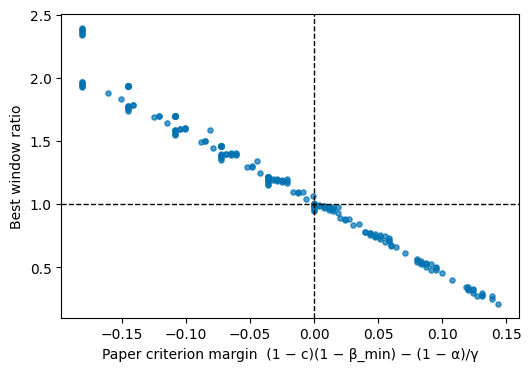

Strains where R is eradicated somewhere on the dose axis (a ratio can be given): 195 of 294; in the other 99 R is never eradicated
Sign of the Eq. 2 margin vs. presence of a window, on this grid: agreement 100.0%
Counting strains where R or S is never eradicated on the dose axis as 'no window': agreement 100.0% over all 294 strains


Spearman correlation between margin and window ratio: -0.995


In [9]:
gamma = BASE_VALUES["gamma"]
js["criterion_margin"] = (1 - js.c) * (1 - js.beta_min) - (1 - js.alpha) / gamma
fig, ax = plt.subplots(figsize=(5.2, 3.6), constrained_layout=True)
ax.scatter(js.criterion_margin, js.best_window_ratio, s=14, color=OKABE_ITO["blue"], alpha=0.7)
ax.axhline(1, color="black", ls="--", lw=1); ax.axvline(0, color="black", ls="--", lw=1)
ax.set_xlabel("Paper criterion margin  (1 − c)(1 − β_min) − (1 − α)/γ"); ax.set_ylabel("Best window ratio")
plt.show()
valid = js.dropna(subset=["best_window_ratio"])
agree = ((valid.criterion_margin < 0) == (valid.best_window_ratio > 1)).mean()
print(f"Strains where R is eradicated somewhere on the dose axis (a ratio can be given): {len(valid)} of {len(js)}; "
      f"in the other {len(js) - len(valid)} R is never eradicated")
print(f"Sign of the Eq. 2 margin vs. presence of a window, on this grid: agreement {agree:.1%}")
no_window_all = js.best_window_ratio.isna() | (js.best_window_ratio <= 1)
print(f"Counting strains where R or S is never eradicated on the dose axis as 'no window': agreement "
      f"{((js.criterion_margin < 0) == ~no_window_all).mean():.1%} over all {len(js)} strains")
print(f"Spearman correlation between margin and window ratio: {valid.criterion_margin.corr(valid.best_window_ratio, method='spearman'):.3f}")

### How sharp is the agreement? A fine check next to the boundary

The joint grid has no strain with a margin between 0 and +0.0038, the R-favoured strip next to the
boundary where exceptions could occur (13 strains with α = 1 lie exactly on the boundary and have no
window; the nearest S-favoured strain is at −0.0012). Here single traits are
moved in small steps across it (i = 10, 36 antibiotic doses between 9 and 12.5), and the window ratio is
measured directly. "Margin with actual ι" uses ι = 0.990 at i = 10 instead of the ι = 1 that Eq. 2 assumes.

In [10]:
from src.analysis.grid_runner import run_points
from src.analysis.dose_window import critical_dose
from src.analysis.kill_protection import IOTA
fine_a0 = np.geomspace(9.0, 12.5, 36)
near = {"base": {}, "c = 0.65": {"c": 0.65}, "c = 0.63": {"c": 0.63}, "c = 0.62": {"c": 0.62}, "c = 0.60": {"c": 0.60},
        "α = 0.9575": {"alpha": 0.9575}, "α = 0.96": {"alpha": 0.96}, "α = 0.9625": {"alpha": 0.9625},
        "β_min = 0.875": {"beta_min": 0.875}, "β_min = 0.85": {"beta_min": 0.85}}
rows = []
for name, over in near.items():
    strain = {k: float(BASE_VALUES[k]) for k in TRAITS} | over
    d = run_points([{**strain, "a0": float(a)} for a in fine_a0]).sort_values("a0")
    ratio = critical_dose(d.a0.values, d.ns_min.values) / critical_dose(d.a0.values, d.nr_min.values)
    rows.append({"strain": name,
                 "Eq. 2 margin": (1 - strain["c"]) * (1 - strain["beta_min"]) - (1 - strain["alpha"]) / gamma,
                 "margin with actual ι": (1 - strain["beta_min"]) * (1 - strain["c"] * IOTA) - (1 - strain["alpha"]) / gamma,
                 "window ratio": ratio, "window exists": ratio > 1,
                 "goal doses among the 36": int(d.goal_met_floor.sum())})
near_table = pd.DataFrame(rows).set_index("strain")
wrong = near_table[(near_table["Eq. 2 margin"] > 0) & near_table["window exists"]]
print(f"Strains the criterion puts on the R-favoured side that still have a window: {len(wrong)} "
      f"(largest margin {wrong['Eq. 2 margin'].max():.4f}, ratios {wrong['window ratio'].min():.3f}-{wrong['window ratio'].max():.3f})")
near_table.round(4)

Strains the criterion puts on the R-favoured side that still have a window: 4 (largest margin 0.0018, ratios 1.002-1.007)


,Eq. 2 margin,margin with actual ι,window ratio,window exists,goal doses among the 36
strain,,,,,
base,-0.0062,-0.0055,1.0437,True,5
c = 0.65,-0.0012,-0.0006,1.0175,True,2
c = 0.63,0.0008,0.0014,1.0070,True,1
c = 0.62,0.0018,0.0024,1.0018,True,0
c = 0.60,0.0038,0.0044,0.9912,False,0
α = 0.9575,-0.0008,-0.0001,1.0128,True,1
α = 0.96,0.0010,0.0017,1.0024,True,0
α = 0.9625,0.0028,0.0035,0.9921,False,0
β_min = 0.875,0.0013,0.0021,1.0031,True,0


## Takeaways

- **A dose that removes R and keeps S exists only for some strains.** 113 of the 294 strains in the
  joint design have a selective window; 112 of them have at least one goal dose on the grid.
- **The window is narrow.** For the base strain the antibiotic dose can be only 4% above the
  R-eradicating dose before S is lost too (ratio 1.04). The widest fully measured window is 2.18 (α = 0.75,
  β_min = 1, i = 0.32); at i ≤ 0.25 the same strains have an open-ended window (S survives every dose up to
  a0 = 100), so the ratio there is at least 2.4. With some private protection left (β_min ≤ 0.9) the
  widest is 1.97 (α = 0.75, β_min = 0.9, c = 1).
  Neighbouring grid doses differ by a factor of 1.26, so narrow windows can fall between grid doses;
  the window ratio is the more reliable measure.
- **Cost of resistance matters most.** Lowering α from 0.95 to 0.75 widens the window from 1.04 to 1.83
  and raises the goal doses from 4 to 40. At α ≥ 0.9625 there is no window at any dose.
- **Private protection closes the window.** With α and c at base, a window needs β_min of about 0.875 or more (ratio 1.003 at 0.875 in the fine check, 1.04 at 0.9; none at 0.85). Costlier
  strains tolerate more private protection (down to β_min = 0.4 at α = 0.75 with c at base). With strong
  private protection (β_min ≤ 0.4) a window needs c ≥ 0.7, and c = 1 unless R is also costly (α ≤ 0.8).
  With no cost of resistance (α = 1) no strain has a window.
- **More inhibitor helps.** In 25 of the 26 single-trait strains that have a window, it is widest at the
  highest inhibitor dose (i = 10). The exception is β_min = 1: β does not depend on the inhibitor there,
  so the window ratio is nearly the same at every inhibitor dose (1.20–1.21).
- **The paper's criterion is a close guide to where a window exists, not an exact rule.** On the joint
  grid the sign of the Eq. 2 margin, (1 − c)(1 − β_min) − (1 − α)/γ, matches the presence of a window in
  all 294 strains, and the window ratio falls steadily as the margin rises (Spearman −0.995). But the grid
  has no strain in the narrow R-favoured strip next to the boundary (margin between 0 and +0.0038). The fine check above shows that strains just on the R-favoured side
  (margin up to about +0.002) still have a very narrow window (ratio ≤ 1.01). One direction is exact: if
  γ(1 − β) < 1 − α, R loses share at every moment, so R always reaches one cell before S.
- **Missing the window is costly in both directions.** Too high a dose eradicates the whole community
  (14% of joint runs); at inhibitor doses with no window, a high antibiotic dose can eradicate S and leave
  R (2.3%).

**Limits.** A single administration of each dose. The window ratio is interpolated from the plain model's
lowest densities and checked against the extinction-floor runs above. "S survives" uses the fixed
viability cut-off (half of the drug-free base S). The joint design uses a coarse trait grid (6 × 7 × 7).
The agreement with the criterion is an empirical result on that grid.